# 07. Information arrival

**Questions.** When in the 24 hours before tipoff do prices move? And how does the price of a team move when the official injury report rules one of its key players Out?

**Plan.** This notebook follows `ANALYSIS_PLAN.md` section 10.4, which was committed before any result here was computed. Part D1 is descriptive and has no test. Part D2 is an event study with one primary test. All tests are two-sided at the 0.05 level.

**Data.**
- `data/processed/price_paths.csv.gz`: each game's normalized midpoint every 5 minutes from 30 hours before tipoff to tipoff, built by `src/build_price_paths.py`.
- `data/processed/injury_report_snapshots_2025_26.csv` and `injury_status_changes_2025_26.csv`: the official NBA injury reports, fetched with the `nbainjuries` package (`envs/injuries/fetch_injury_reports.py`, `src/injury_events.py`).
- `data/processed/injury_event_check_2025_26.csv`: the check of 20 randomly drawn events against the original report files (`envs/injuries/check_events.py`).
- `data/processed/player_minutes_2025_26.csv`: minutes per player per game, from `nba_api` (`src/player_minutes.py`).

**Seed.** The bootstrap uses seed 4981 and 2,000 replicates, as in the plan.

**Primary test.** The mean change in the affected team's price around the release of the report, against zero (section 5). It is one of the 8 primary tests of Stage 10. Its Holm adjusted p value is in `results/stage10_all_tests.csv`, written by notebook 10.

In [1]:
import sys
sys.path.insert(0, "../src")

import pandas as pd
from IPython.display import display

import all_tests
import information_arrival as ia
import injury_events
from csv_io import read_csv, write_csv
from stats_tools import B, SEED

ia.RESULTS_DIR.mkdir(exist_ok=True)
print(f"Bootstrap: B = {B:,}, seed = {SEED}")

Bootstrap: B = 2,000, seed = 4981


# Part D1. When do prices move (descriptive)

## 1. Price changes per 5-minute step

For every main-sample game and every 5-minute step, the absolute change in logit(p) from the step before, where p is the normalized home midpoint. A change exists only when both steps have a midpoint. The average at each step is taken over the games that have a change there.

The main range is 24 hours before tipoff to tipoff. The steps before 24 hours are shown apart, in gray. The raw data starts 30 hours before tipoff and holds no earlier quote, so a game has no price in that range until its first quote of the window arrives.

1,229 games, 439,610 step changes out of 442,440 possible


,minutes_to_tipoff,mean_abs_change,game_steps,games_possible,hours_to_tipoff,range
0,1795,NaN,0,1229,29.9167,30h to 24h
36,1615,0.0101,1222,1229,26.9167,30h to 24h
72,1435,0.0093,1222,1229,23.9167,24h to tipoff
144,1075,0.0039,1227,1229,17.9167,24h to tipoff
216,715,0.0041,1228,1229,11.9167,24h to tipoff
288,355,0.0084,1229,1229,5.9167,24h to tipoff
324,175,0.0048,1229,1229,2.9167,24h to tipoff
348,55,0.0080,1229,1229,0.9167,24h to tipoff
354,25,0.0085,1229,1229,0.4167,24h to tipoff
359,0,0.0106,1229,1229,0.0,24h to tipoff


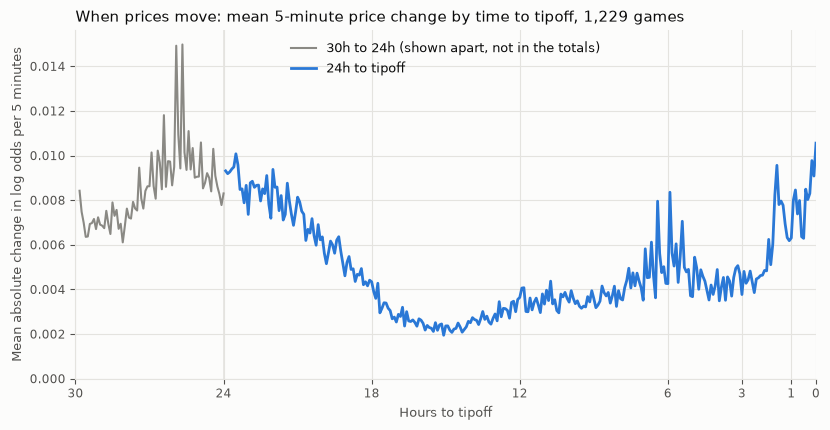

In [2]:
paths = ia.load_paths()
changes = ia.step_changes(paths)
minutes = ia.by_minutes(changes)
write_csv(minutes, ia.RESULTS_DIR / "arrival_by_minutes.csv")
n_games = paths["game_id"].nunique()
print(f"{n_games:,} games, {changes['abs_change'].notna().sum():,} step changes out of "
      f"{len(changes):,} possible")
display(minutes.iloc[[0, 36, 72, 144, 216, 288, 324, 348, 354, 359]].round(4))
fig = ia.minutes_figure(minutes, n_games, ia.RESULTS_DIR / "arrival_by_minutes.png")

**Scale.** A change of 0.01 in log odds is about a quarter of a percentage point for a price near 50%. So the average 5-minute move is small at every hour.

**Shape.** Inside the main range, the average change per 5 minutes is highest at the two ends and lowest in the middle.
- Around 24 hours before tipoff it is about 0.009.
- It falls to its minimum, 0.0019, about 15 hours before tipoff. For an evening game that is the middle of the night.
- It rises again through the game day, with single-step spikes around 6 hours before tipoff.
- It is highest in the last hour, and the last step before tipoff has the largest value, 0.0106.

**Before 24 hours (gray).** From 30 to 24 hours before tipoff the average is 0.0085 per step, about the same level as at 24 hours. For an evening game these hours are the afternoon and evening of the day before. Apart from the first two steps, nearly every game has a price there (1,222 games per step at the median).

## 2. By clock time on the game day

The same changes, grouped by the US Eastern clock time at which the step ends, for steps on the game's own date. A step at 6:00 pm is 60 minutes before a 7:00 pm tipoff and 4.5 hours before a 10:30 pm tipoff, so this view mixes games at different distances from tipoff. Clock bins with fewer than 50 game-steps are not plotted.

,clock_time_et,mean_abs_change,game_steps,games
269,22:25,0.0105,56,56
264,22:00,0.0100,184,184
268,22:20,0.0098,56,56
270,22:30,0.0095,56,56
261,21:45,0.0095,184,184
250,20:50,0.0088,324,324
244,20:20,0.0087,377,377
157,13:05,0.0085,1212,1212


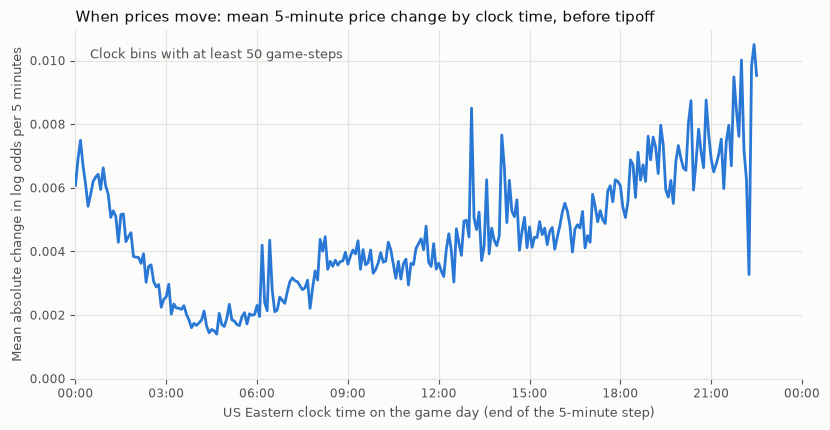

In [3]:
clock = ia.by_clock(changes)
write_csv(clock, ia.RESULTS_DIR / "arrival_by_clock.csv")
top = clock[clock["plotted"] == 1].nlargest(8, "mean_abs_change")
display(top[["clock_time_et", "mean_abs_change", "game_steps", "games"]].round(4))
fig = ia.clock_figure(clock, ia.RESULTS_DIR / "arrival_by_clock.png")

**Through the day.** The average change is lowest in the early morning, under 0.002 between about 4 and 5 am Eastern. It rises through the morning and afternoon. The evening bins are the highest (mostly 0.007 to 0.010 after 8 pm), but they hold only the games that tip off late, and those steps are close to tipoff.

**Spikes.** The largest daytime bins are single 5-minute steps just after the hour: 1:05 pm (0.0085) and 2:05 pm (0.0077), about twice the level of the bins around them. Both come from more than 1,200 games. This section attaches no test and does not identify what causes them.

## 3. Share of the movement in each window

The sum of absolute changes in each window, divided by the sum over the four windows from 24 hours to tipoff, pooled over games. `share_per_hour` divides by the window's length, because the windows are not equally long. The 30h to 24h window is the last row. It is not part of the total.

In [4]:
shares = ia.window_shares(changes)
write_csv(shares, ia.RESULTS_DIR / "arrival_window_shares.csv")
display(shares.round(4))

,window,minutes_from,minutes_to,hours,sum_abs_change,game_steps,game_steps_possible,mean_abs_change_per_step,share_of_24h_total,share_per_hour,in_24h_total
0,24h to 6h,1440,360,18.0,1207.7646,264931,265464,0.0046,0.7077,0.0393,1
1,6h to 1h,360,60,5.0,377.4541,73740,73740,0.0051,0.2212,0.0442,1
2,1h to 30 min,60,30,0.5,54.6812,7374,7374,0.0074,0.0320,0.0641,1
3,last 30 min,30,0,0.5,66.6775,7374,7374,0.0090,0.0391,0.0781,1
4,30h to 24h,1800,1440,6.0,735.3780,86191,88488,0.0085,NaN,NaN,0


- **24h to 6h:** 70.8% of the movement, in 18 hours. That is 3.9% per hour.
- **6h to 1h:** 22.1%, in 5 hours. 4.4% per hour.
- **1h to 30 min:** 3.2%, in half an hour. 6.4% per hour.
- **Last 30 min:** 3.9%, in half an hour. 7.8% per hour.

Most of the movement happens more than 6 hours before tipoff, simply because that window is long. Per hour, prices move fastest in the last hour: about twice as fast in the last 30 minutes as in an average hour from 24h to 6h.

**30h to 24h (not in the total).** Its sum of changes is 735, against 1,208 for the 18 hours that follow, so per step it is as active as the last half hour (0.0085 against 0.0090). 86,191 of its 88,488 possible game-steps have a change (97%). The plan expected this window to be badly understated. It is not: only its first two steps are missing many games.

# Part D2. Injury report event study

## 4. From the injury reports to events

**Source.** Every snapshot of the official NBA injury report for the 2025-26 regular season: hourly until December 19, 2025 and every 15 minutes from December 22, 2025. The release time of a snapshot is the time the file was posted on the NBA's server (its `Last-Modified` time), when that lies from 30 minutes before to 60 minutes after the scheduled report time. Otherwise it is the scheduled time.

**Reliability rule (fixed in the plan).** D2 runs only if at least 95% of the snapshots on the server were fetched and parsed, at least 95% of the main-sample games appear with both teams in a parsed snapshot, and a hand check of 20 random events against the original files finds no error.

In [5]:
loaded = injury_events.load_events()
snapshots, events = loaded["snapshots"], loaded["events"]
games_seen = pd.read_csv(injury_events.PROCESSED / "injury_report_games_2025_26.csv", dtype=str)
check = pd.read_csv(injury_events.CHECK_PATH, dtype=str, keep_default_na=False)
reliability = injury_events.reliability(snapshots, games_seen,
                                        read_csv(injury_events.GAME_MAP_PATH), check)
write_csv(reliability, ia.RESULTS_DIR / "injury_reliability.csv")
print(f"{len(snapshots):,} snapshot file names, {(snapshots['on_server'] == 1).sum():,} on "
      f"the server, {(snapshots['parsed'] == 1).sum():,} parsed")
display(reliability.round(4))
releases = loaded["releases"]
used = releases[releases["report_file"].isin(snapshots.loc[snapshots["parsed"] == 1,
                                                           "report_file"])]
print("release time of the parsed snapshots:", used["release_source"].value_counts().to_dict())
print("posting time minus scheduled time, in minutes, where the posting time is used:")
display(used.loc[used["release_source"] == "posted", "posted_lag_min"].describe().round(2)
        .to_frame().T)

12,237 snapshot file names, 11,753 on the server, 11,753 parsed
release time of the parsed snapshots: {'posted': 11752, 'scheduled': 1}
posting time minus scheduled time, in minutes, where the posting time is used:


,check,count,out_of,share,required_share,passes
0,snapshots on the server that were fetched and ...,11753,11753,1.0,0.95,1
1,main-sample games in a parsed snapshot with bo...,1229,1229,1.0,0.95,1
2,events of the hand check that agree with the r...,20,20,1.0,1.00,1


,count,mean,std,min,25%,50%,75%,max
posted_lag_min,11752.0,0.1,0.05,0.05,0.07,0.08,0.1,1.0


All three checks pass, so D2 runs.

- **Snapshots.** The season has 12,237 snapshot file names. 11,753 exist on the server, and all of them were fetched and parsed. The 484 that do not exist are the 480 of the All-Star break (February 13 to 17) and 4 on March 8, 2026, the hour skipped when the clocks changed.
- **Games.** All 1,229 main-sample games appear, with both teams, in at least one parsed snapshot.
- **Hand check.** 20 events were drawn at random (seed 4981). For each one, the player, the game, his status in the snapshot of the event, his status in the snapshot before it, and the report time were looked up again in the two original PDF files, by reading their plain text instead of the parsed table. All 20 agree. Two of them were also read line by line.

**Release time.** Every parsed snapshot but one uses its posting time. The file is posted a median of 5 seconds after the scheduled report time, and at most 1 minute after. The one exception is the 1:30 am report on November 2, 2025, the night the clocks changed back. Its scheduled time is ambiguous, and no event falls on it.

**Definitions (fixed in the plan).**

- **Status change to Out.** A player is Out in a snapshot and was not Out in the snapshot before it: he was listed with another status, or he was not listed while his team had already submitted its report for that game. A team's first submitted report creates no events. Only the first snapshot in which a player is Out for a game counts.
- **Key player.** Top 3 on his team in minutes per game played for that team, over the team's games before that game, with at least 5 such games.
- **Event.** One team in one game at one snapshot with at least one key player changing to Out, released at least 30 minutes before tipoff. If both teams of a game have an event in the same snapshot, both are dropped.
- **Event change.** The affected team's normalized midpoint 30 minutes after the release minus its value 5 minutes before, in probability units. A drop is negative. The price before is the last 5-minute step at or before 5 minutes before the release, and the price after is the first step at or after 30 minutes after it.
- **Placebo.** The same window 3 hours earlier, for the same game and team.
- **Anticipation window (secondary).** From 60 minutes before the release to 5 minutes before it.

In [6]:
event_changes = ia.event_changes(events, paths)
counts = ia.event_counts(loaded["counts"], event_changes)
write_csv(counts, ia.RESULTS_DIR / "injury_event_counts.csv")
keep = ["event_id", "game_id", "game_date", "team", "side", "home_team", "away_team",
        "report_file", "prev_report_file", "players", "prev_statuses", "n_key_players",
        "best_minutes_rank", "tipoff_utc", "scheduled_utc", "posted_utc", "release_utc",
        "release_source", "minutes_before_tipoff", "step_before", "step_after",
        "step_anticipation", "price_before", "price_after", "price_anticipation", "change",
        "anticipation_change", "placebo_change", "placebo_anticipation_change",
        "change_minus_placebo", "anticipation_minus_placebo"]
write_csv(event_changes[keep], ia.RESULTS_DIR / "injury_events.csv")
display(counts)

,step,count
0,"status changes, all kinds",18546
1,changes to Out between consecutive snapshots,11559
2,"of those, the player's first Out for the game",11545
3,"of those, team had submitted in the earlier sn...",2169
4,"of those, no unparsed snapshot in between",2169
5,"of those, team name not recognized",0
6,"of those, for a main-sample game",2168
7,changes to Out with the name matched to a player,2114
8,changes to Out by a key player,383
9,"events (team, game, snapshot)",361


**From changes to events.**
- The reports hold 11,559 changes to Out between consecutive snapshots, 11,545 of them a player's first for the game. Most are not news: 9,376 come in a team's first submitted report for a game, which lists every long-term absence at once. 2,169 come after the team had already submitted.
- 2,114 of those are matched by name to a player in that team's game logs. The other 54 are players who did not play for the team in the season.
- 383 are by a key player. They make 361 events (one team, one game, one snapshot).
- 10 events are dropped because both teams have one in the same snapshot, and 49 because the report came out less than 30 minutes before tipoff.

**The 302 events.** Every one has both midpoints of the main window, the placebo window and the anticipation window, and 301 have the placebo of the anticipation window. All use the posting time as the release time. They fall on 127 game dates.

**What they look like.** In 180 events the player was Questionable before, in 70 Doubtful, in 27 not listed, in 3 Probable and in 2 Available. The other 20 events have two or three key players at once. Half of the events were released 90 minutes or less before tipoff, a quarter 60 minutes or less, and a quarter more than 5 hours before.

## 5. The test

The mean event change against zero, with the block bootstrap by game date: events of the same date are drawn together. **The first row is the primary test.** The other rows are secondary: the placebo mean, the mean of event change minus placebo change, and the same three for the anticipation window.

In [7]:
results, tests = ia.event_tests(event_changes)
write_csv(results, ia.RESULTS_DIR / "injury_event_test.csv")
write_csv(tests, all_tests.part_path(ia.PART))
display(results.round(4))
main = ia.study_samples(event_changes)["main"]
display(main[["change", "placebo_change", "anticipation_change", "minutes_before_tipoff"]]
        .describe().round(4))

,test_id,window,statistic,n_events,n_dates,mean,median,sd,share_negative,boot_lo,boot_hi,p_bootstrap
0,injury_event_mean,main,change,302,127,-0.0089,-0.0030,0.0197,0.5662,-0.0113,-0.0067,0.0010
1,injury_event_placebo_mean,main,placebo_change,302,127,0.0000,0.0000,0.0068,0.2252,-0.0007,0.0008,0.9935
2,injury_event_minus_placebo,main,change_minus_placebo,302,127,-0.0089,-0.0032,0.0213,0.5695,-0.0115,-0.0066,0.0010
3,injury_anticipation_mean,anticipation,anticipation_change,302,127,-0.0063,0.0000,0.0215,0.4570,-0.0086,-0.0042,0.0010
4,injury_anticipation_placebo_mean,anticipation,placebo_anticipation_change,301,127,-0.0003,0.0000,0.0078,0.2625,-0.0012,0.0004,0.4378
5,injury_anticipation_minus_placebo,anticipation,anticipation_minus_placebo,301,127,-0.0058,-0.0011,0.0226,0.5150,-0.0085,-0.0034,0.0010


,change,placebo_change,anticipation_change,minutes_before_tipoff
count,302.0000,302.0000,302.0000,302.0000
mean,-0.0089,0.0000,-0.0063,181.3930
std,0.0197,0.0068,0.0215,182.4045
min,-0.0850,-0.0343,-0.2521,44.8833
25%,-0.0124,0.0000,-0.0083,59.9167
50%,-0.0030,0.0000,0.0000,89.9000
75%,0.0000,0.0000,0.0000,314.9333
max,0.0500,0.0662,0.0424,1559.9000


**Primary test.** The affected team's price falls by 0.89 percentage points on average, from 5 minutes before the release to 30 minutes after. The bootstrap interval is -1.13 to -0.67 points, and the bootstrap p value is 0.001, the smallest value 2,000 replicates can give.

- The typical event is smaller than the mean: the median change is -0.30 points. 57% of the events are negative, 27% show no change and 16% are positive. The largest drop is 8.5 points.
- **Placebo.** In the same window 3 hours earlier, the mean change is 0.00 points (interval -0.07 to +0.08, p = 0.99).
- **Event minus placebo.** -0.89 points (interval -1.15 to -0.66, p = 0.001).

**Anticipation window (secondary).** From 60 minutes before the release to 5 minutes before, the price already falls by 0.63 points on average (interval -0.86 to -0.42, p = 0.001). Its placebo is -0.03 points (p = 0.44), and the difference is -0.58 points (interval -0.85 to -0.34, p = 0.001).

**What the numbers show.** Prices respond to the official report: the team's price drops when a key player is ruled Out, and nothing like it happens 3 hours earlier. But the report is not the first the market hears of it. About 0.6 points of the fall come in the hour before the file is posted, and 0.9 points around the posting itself.

**Limits.**
- The change measures the market's move in this window. It is not the full effect of the player's absence: most of these players were already listed as Questionable or Doubtful, so part of the risk was in the price before.
- The release time is when the file appeared on the NBA's server. Teams and reporters can make the news public earlier, which is one way the price could move before the release. The data here cannot tell that apart from other explanations.

## 6. The average price path around the release

For the events of the main window, the affected team's price from 60 minutes before to 120 minutes after the release, minus its value 5 minutes before the release. Each event is lined up on the step used as its price before. Steps after tipoff are left out, so the number of events behind each point falls toward the right. The band is the pointwise 95% bootstrap interval.

,offset_min,mean_relative_price,n_events,boot_lo,boot_hi
0,-60,0.0063,302,0.0042,0.0086
3,-45,0.0050,302,0.0034,0.0068
6,-30,0.0038,302,0.0023,0.0054
9,-15,0.0030,302,0.0018,0.0042
12,0,-0.0033,302,-0.0045,-0.0021
15,15,-0.0086,302,-0.0109,-0.0065
18,30,-0.0088,302,-0.0112,-0.0065
21,45,-0.0089,302,-0.0114,-0.0066
24,60,-0.0103,271,-0.0132,-0.0078
27,75,-0.0111,216,-0.0146,-0.0080


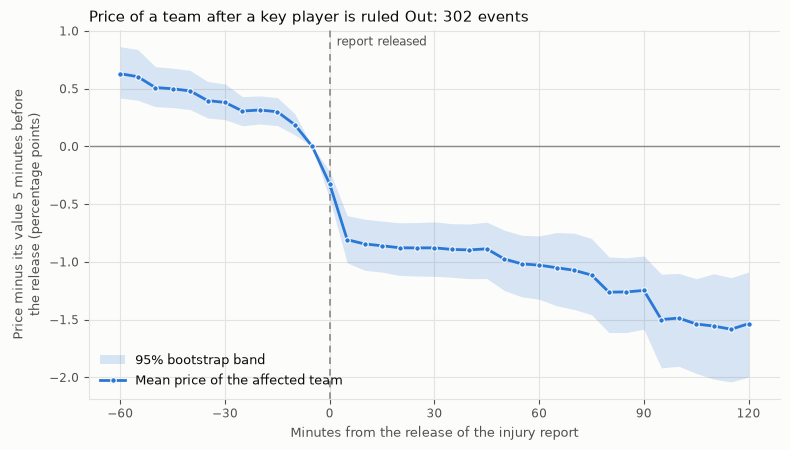

In [8]:
path_rows = ia.event_paths(event_changes, paths)
path_table = ia.average_path(path_rows)
write_csv(path_table, ia.RESULTS_DIR / "injury_event_path.csv")
display(path_table.iloc[::3].round(4))
fig = ia.path_figure(path_table, len(main), ia.RESULTS_DIR / "injury_event_path.png")

- **Before the release.** One hour before, the price is 0.63 points above its value at 5 minutes before. It falls steadily toward the release.
- **At the release.** The price falls 0.33 points in the 5 minutes that end at the posting time, and it is 0.81 points down 5 minutes after it. Most of the reaction is complete within 5 to 10 minutes.
- **After.** From 10 to 45 minutes after the release the mean is flat, near -0.88 points.
- **Later points.** The line keeps falling, to about -1.5 points at 120 minutes. But fewer events reach that far before tipoff: 271 at 50 minutes, 184 at 80 and 118 at 120. The later points describe the events released early, so the steps down partly reflect a change in which events are averaged.

## 7. All tests of this notebook

The tests of section 5 in the common Stage 10 layout. `p_bound` is min(1, 8 · p) for the primary test. The Holm value itself is added by notebook 10.

In [9]:
shown = tests[["test_id", "role", "n", "unit", "estimate", "ci_lo", "ci_hi", "p_raw"]].copy()
shown["p_bound"] = all_tests.bonferroni_bound(shown["p_raw"]).where(shown["role"] == "primary")
display(shown.round(4))

,test_id,role,n,unit,estimate,ci_lo,ci_hi,p_raw,p_bound
0,injury_event_mean,primary,302,events,-0.0089,-0.0113,-0.0067,0.0010,0.008
1,injury_event_placebo_mean,secondary,302,events,0.0000,-0.0007,0.0008,0.9935,NaN
2,injury_event_minus_placebo,secondary,302,events,-0.0089,-0.0115,-0.0066,0.0010,NaN
3,injury_anticipation_mean,secondary,302,events,-0.0063,-0.0086,-0.0042,0.0010,NaN
4,injury_anticipation_placebo_mean,secondary,301,events,-0.0003,-0.0012,0.0004,0.4378,NaN
5,injury_anticipation_minus_placebo,secondary,301,events,-0.0058,-0.0085,-0.0034,0.0010,NaN


**Primary test.** `injury_event_mean` has p = 0.001. Its bound 8 · p is 0.008, so it is significant after the Holm adjustment whatever the other primary tests give.

**Secondary tests.** Three of the five have p = 0.001: the event change minus its placebo, the anticipation change, and the anticipation change minus its placebo. The two placebo means are not distinguishable from 0 (p = 0.99 and 0.44).

**In short.** The official injury report moves the price of the affected team down by about 0.9 points within minutes, and the price has already moved about 0.6 points in the hour before.

---

# Exploratory (not in the Stage 10 plan): events by the player's previous status

**This section was added after the Stage 10 results above were seen.** It follows `ANALYSIS_PLAN.md`, "Exploratory, added after Stage 10 results", check X1, which was committed before this was run. Its results carry less weight than the planned test in section 5. They are in `results/stage10_all_tests.csv` with the role `exploratory` and get no Holm adjustment.

**Reason.** Section 5 pools events in which the player was Questionable, Doubtful or not listed before he was ruled Out. A player who was Doubtful was already expected to miss the game, and one who was not listed was not. This check asks whether the size of the price change goes with how much of a surprise the news was.

**What is computed.** The 302 events of section 5 are grouped by the previous status of their key players. An event is in a group when every one of its key players had that status. For each group, the mean change in the main window (5 minutes before the release to 30 minutes after) and in the anticipation window (60 to 5 minutes before), with a block bootstrap by game date inside the group. Events that fit no group are counted in the row `other` and get no test. No test of a difference between groups is run.

In [10]:
by_status, status_tests = ia.status_split(event_changes)
write_csv(by_status, ia.RESULTS_DIR / "exploratory_injury_by_status.csv")
write_csv(status_tests, all_tests.part_path("exploratory_information_arrival"))
display(by_status.round(4))

,status_group,window,n_events,n_dates,mean,median,share_negative,boot_lo,boot_hi,p_bootstrap
0,Questionable,main,193,104,-0.0128,-0.0081,0.6528,-0.0163,-0.0097,0.0010
1,Questionable,anticipation,193,104,-0.0082,-0.0012,0.5181,-0.0117,-0.0053,0.0010
2,Doubtful,main,72,54,-0.0004,0.0000,0.4028,-0.0022,0.0014,0.6167
3,Doubtful,anticipation,72,54,-0.0007,0.0000,0.3333,-0.0030,0.0016,0.5337
4,not listed,main,27,23,-0.0063,0.0000,0.4074,-0.0132,-0.0015,0.0040
5,not listed,anticipation,27,23,-0.0059,0.0000,0.3333,-0.0152,0.0011,0.1279
6,other,main,10,10,-0.0017,-0.0025,0.5000,NaN,NaN,NaN
7,other,anticipation,10,10,-0.0102,-0.0025,0.5000,NaN,NaN,NaN


**Counts.** 193 events are Questionable, 72 Doubtful and 27 not listed. 10 events fit no group (3 Probable, 2 Available, 5 with a Questionable and a Doubtful player) and are only counted.

**Questionable (193 events, 104 dates).**
- Main window: the price falls 1.28 points on average (bootstrap -1.63 to -0.97, p = 0.001). The median is -0.81 points, and 65% of the events are negative.
- Anticipation window: it falls 0.82 points in the hour before (bootstrap -1.17 to -0.53, p = 0.001).

**Doubtful (72 events, 54 dates).**
- Main window: -0.04 points (bootstrap -0.22 to +0.14, p = 0.62).
- Anticipation window: -0.07 points (bootstrap -0.30 to +0.16, p = 0.53).

**Not listed (27 events, 23 dates).**
- Main window: -0.63 points (bootstrap -1.32 to -0.15, p = 0.004). The median is 0: in 14 of the 27 events the price did not move.
- Anticipation window: -0.59 points (bootstrap -1.52 to +0.11, p = 0.13).

**What the numbers show.** The pooled result of section 5 comes from the Questionable events. When a Doubtful player is ruled Out, the price does not move, at the release or before it. That fits a market that had already priced a Doubtful player as absent. The not listed events fall less than the Questionable ones on average, and their interval is wide.

**Limits.**
- This check was chosen after seeing the results, and no test compares the groups with each other. The intervals of the Questionable and Doubtful groups do not overlap in the main window, but that is a reading of the table, not a planned test.
- The not listed group has 27 events, and its mean rests on a minority of them.
- The groups can differ in more than the status. The not listed reports came out later (a median of 60 minutes before tipoff, against 90 for the other two groups), and the players are not the same.